# 28. Скульптура в коротком пакете

[Программа курса](../../README_ru.md)

На отложенной фотографии уже заметен предел модели из 117 пятен: гладкие грани скульптуры слегка расплылись. Теперь появится ещё один источник ошибки. Запишем модель компактнее и нарисуем тот же ракурс из прочитанных байтов. Сравнивать будем с рендером до упаковки, чтобы два вида размытия не смешались.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
course = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "compression_math.py").is_file())
if str(course) not in sys.path:
    sys.path.insert(0, str(course))
import json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
import compression_math as codec
import compression_demos as demos
from reconstruction import scores, benchmark
from splat_render import render_scene, orbit_camera
lang = "ru"

## Первые восемь байт

За началом файла нет никакой магии. Первые четыре байта — буквы `GSC1`. Следующий байт хранит число байтов на параметр, ещё один — число цветовых каналов. Последние два задают число пятен, младший байт идёт первым. При 117 пятнах это 117 и 0, потому что $117+256\cdot0=117$. Весь заголовок занимает $4+1+1+2=8$ байт.

С постоянным RGB каждое пятно хранит 14 чисел в порядке «центр, ширины, кватернион, непрозрачность, цвет». Если каждое число отдать в float32, файл займёт $8+117\cdot14\cdot4=6560$ байт. Преобразование из исходных чисел двойной точности уже округляет последние разряды.

In [2]:
scene, frames = codec.photo_data()
raw = codec.pack_static(scene, 'f32')
print(raw[:8], list(raw[4:8]), len(raw))
decoded = codec.unpack_static(raw)
print('x:', scene['splats'][0]['center'][0], '→', decoded['splats'][0]['center'][0])

b'GSC1\x04\x03u\x00' [4, 3, 117, 0] 6560
x: 1.4339829476167152 → 1.4339829683303833


## Координата за один байт

Пусть значение $x=1.5$ м попало между краями $a=1$ и $b=3$ м. Длина интервала $b-a=2$ м. Доля пути от левого края равна $(1.5-1)/2=0.25$, единицы сократились. У восьми бит $2^8=256$ кодов от 0 до 255. Между ними 255 промежутков. Доля 0.25 находится на позиции $0.25\cdot255=63.75$. Ближайший код — 64. При чтении $64/255\approx0.25098$. Вернём метры: $1+2\cdot64/255\approx1.50196$ м. Сдвиг около двух миллиметров.

$$
q=\left\lfloor255\frac{x-a}{b-a}+0.5\right\rfloor,\qquad \hat{x}=a+(b-a)\frac{q}{255}.
$$

Здесь $q$ — целый код, скобки ⌊…⌋ означают округление вниз после прибавления половины, а «крышка» у $\hat{x}$ отмечает восстановленное значение. Если оба края совпадают, код будет 0 и декодер просто вернёт этот край. У трёх координат и трёх ширин свои пары краёв. Двенадцать float32 добавляют $12\cdot4=48$ байт. Нормированный кватернион умещается по компонентам от −1 до 1, цвет и непрозрачность — от 0 до 1. Их края известны заранее. Рендерер при переводе кватерниона в матрицу снова нормирует его длину.

Вся сцена теперь занимает $8+48+117\cdot14=1694$ байта. Для одного-единственного пятна заголовок с диапазонами может съесть всю экономию.

In [3]:
display(demos.codec_lab(28, lang))

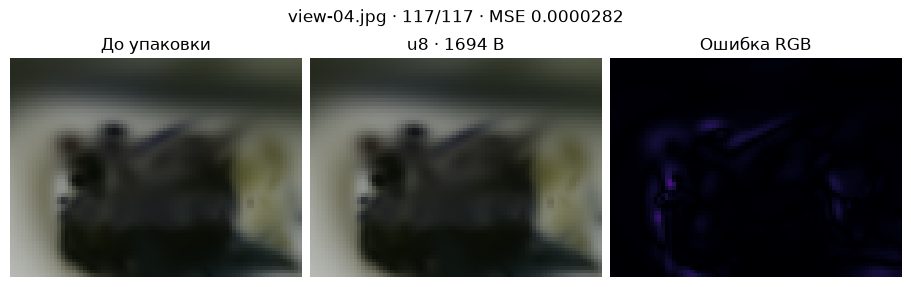

In [4]:
demos.static_figure(lang)
plt.show()

## Какие пятна выкинуть

У двух пятен одинаковые ширины 0.4 и 0.2 м вдоль их самых длинных осей. При непрозрачности 0.8 первое получит оценку $0.8\cdot0.4\cdot0.2=0.064$ м². При непрозрачности 0.1 второе наберёт только 0.008 м². Оставим пятна с большим произведением. Это дешёвая оценка того, сколько места они могут занять в картинке. В ней нет расстояния до камеры, перекрытия передним планом и контраста с фоном. Маленький яркий блик на тёмной поверхности легко потерять. Список отсортирован только для выбора пятен. Уцелевшие строки записываются в исходном порядке.

При доле 50% половина от 117 равна 58.5. Округляем вверх, получаем 59 пятен и $56+59\cdot14=882$ байта. Другой рычаг — цвет. Если вместо трёх каналов оставить их среднее, например $(0.9+0.3+0)/3=0.4$, декодер выдаст $(0.4,0.4,0.4)$. Это учебное среднее каналов, без поправки на восприятие яркости. Один код вместо трёх экономит два байта на пятно, но красный и зелёный с тем же средним становятся неразличимыми.

f32-rgb 6560 B; MSE 0.0 frame ms 58.594


u8-rgb 1694 B; MSE 2.82e-05 frame ms 61.921
u8-half 882 B; MSE 0.0043138 frame ms 32.381


u8-gray-half 764 B; MSE 0.0046234 frame ms 32.194


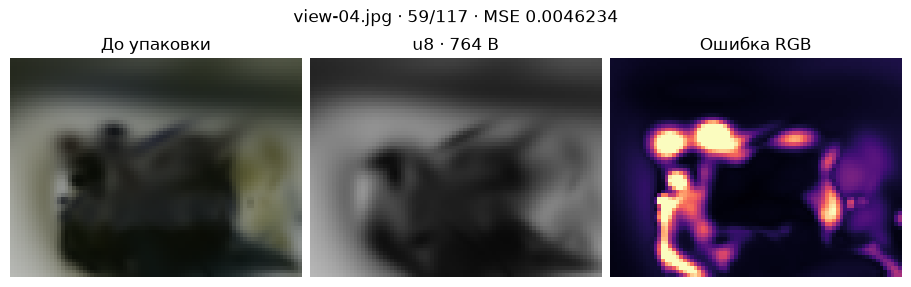

In [5]:
ref = render_scene(scene, frames['view-04.jpg']['camera'], 80, 60)
for name, precision, keep, color in codec.static_candidates():
    data = codec.pack_static(scene, precision, keep, color)
    model = codec.unpack_static(data)
    def draw():
        return render_scene(model, frames['view-04.jpg']['camera'], 80, 60)
    print(name, len(data), 'B; MSE', round(scores(draw(), ref)['mse'], 7),
          'frame ms', round(benchmark(draw, repeats=3), 3))
demos.static_figure(lang, keep=50, color='gray')
plt.show()

## Как читать сравнение

Шкала карты ошибок на рисунках остаётся от 0 до 0.2. Каждый её пиксель — среднее трёх абсолютных разностей. MSE в заголовке рисунка усредняет **квадраты** тех же разностей по всем пикселям и каналам. Замер времени прогревает рендерер, затем берёт медиану повторов. В браузере быстрые вызовы собираются в серию и время делится на её длину. Все варианты декодируются в один и тот же тип сцены. Переход на uint8 сам по себе не уменьшил число операций смешивания, а удаление 58 пятен действительно сократило его.

**Опыт.** Сколько байт уйдёт на 59 серых пятен в uint8? Какой выигрыш даст тот же приём при float32?

<details>
<summary>Разбор</summary>

У серого пятна 12 чисел, поэтому $56+59\cdot12=764$ байта. Цвет занимал на $882-764=118$ байт больше. В float32 разница составит $59\cdot2\cdot4=472$ байта. Оттенок исчезает в обоих случаях.

</details>